# <center> Feature Extraction

---

## Importing Libraries

In [ ]:
# Our usual imports
import matplotlib.pyplot as plt
import numpy as np
from skimage.io import imread

# Importing two different features from skimage to implement
from skimage.feature import canny, multiscale_basic_features

## Image Path, Image Array, Visualization
* We shall use this Image:- https://drive.google.com/uc?id=1tCnjKPGQwGZpIQBNsFXgnwYBxPIV0ngj

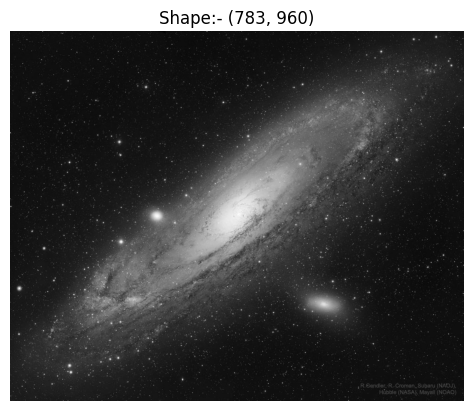

In [ ]:
# Image Path (Image from google drive)
img_path = 'https://drive.google.com/uc?id=1tCnjKPGQwGZpIQBNsFXgnwYBxPIV0ngj'

# Image Array
gray_img_arr = imread(img_path, as_gray=True)

# Visualizing the original Image
plt.imshow(gray_img_arr, cmap='gray')
plt.title(f'Shape:- {gray_img_arr.shape}')
plt.axis('off')
plt.show()

<u>Andomerda Galaxy - Labelled Image</u>               
<img src='https://www.cloudynights.com/uploads/monthly_08_2021/post-233044-0-26674200-1629315618.jpg' width=50%>

## 2) Canny
* Detecting Edges in an image using the Canny algorithm
* [skimage Documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.canny)
* It is widely used edge detection algorithm around the world!
* Change Sigma values and see the outputs

In [ ]:
# Apply canny on gray_img_arr
std=0.5
canny_output = canny(gray_img_arr, sigma=std)

In [ ]:
# Output of canny
print('Shape:-', canny_output.shape)

Shape:- (783, 960)


In [ ]:
# Define Multiple Colormaps to visualize the output
SPECTRAL_LIST = ["gray","jet","hot","prism","nipy_spectral"]

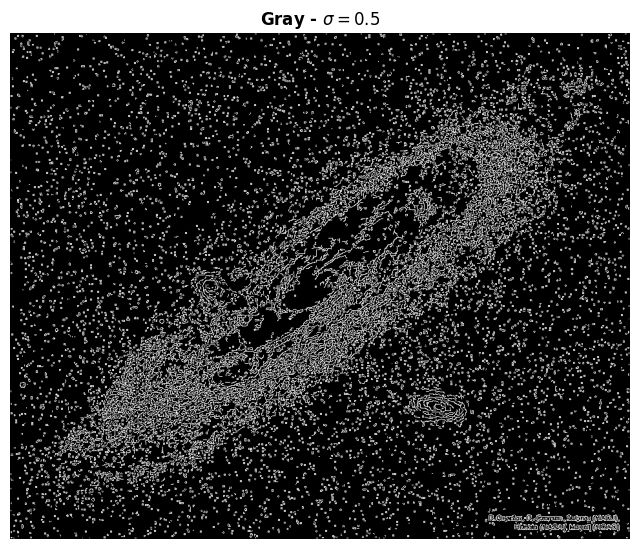

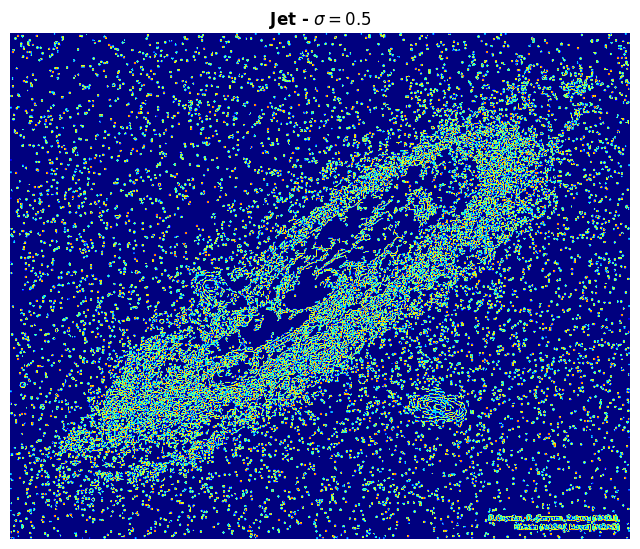

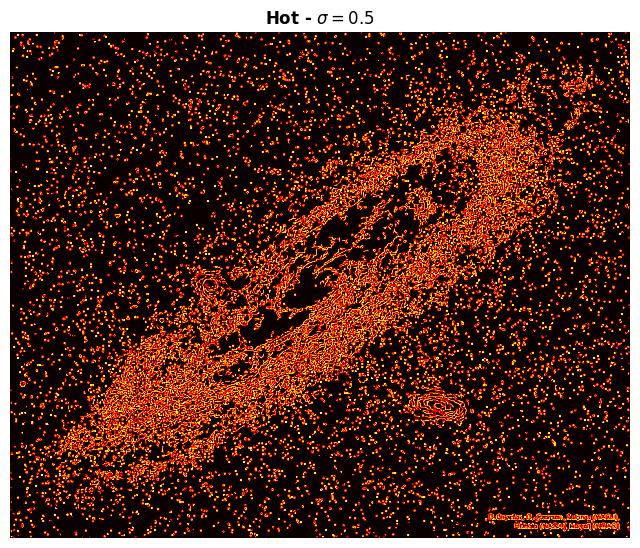

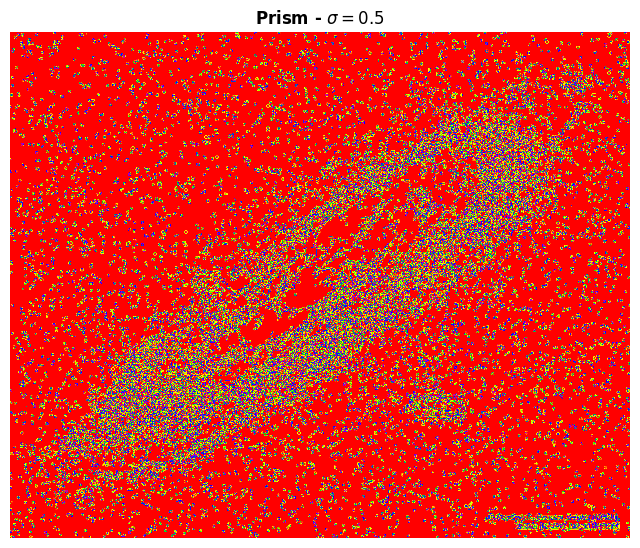

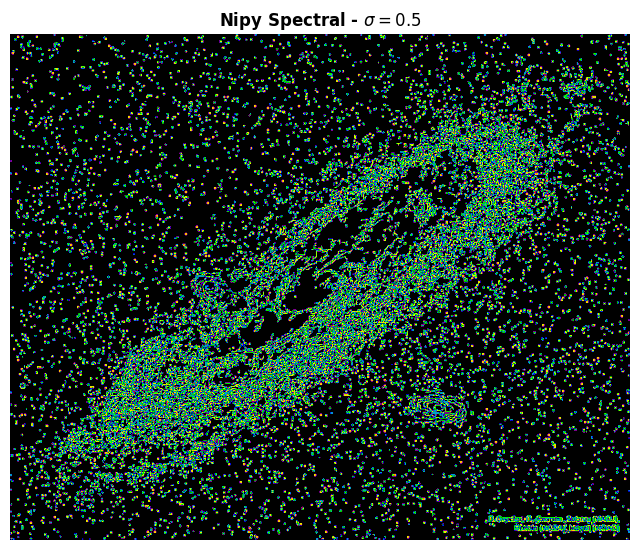

In [ ]:
# Apply all the colormaps on the output of canny
for colormap in SPECTRAL_LIST:
  plt.figure(figsize=(8,8))
  plt.imshow(canny_output, cmap=colormap); plt.axis('off')
  plt.title(f'{" ".join(colormap.title().split("_"))} - $\sigma={std}$', weight='bold')
plt.show()

- Clearly, now we can see the satellite galaxies of Andromeda.

## 3) Basic Multiscale Features

* Intensity (gaussian), gradient intensity (sobel on gaussian) and local structure are computed at different scales
* [skimage Documentation](https://scikit-image.org/docs/stable/api/skimage.feature.html#skimage.feature.multiscale_basic_features)

In [ ]:
# If num_sigma is None, total sigma = 0.5, 1, 2, 4, 8, 16 --> Total 6
# Hence, 6 scales for intensity, 6 scales for gradient intensity and 6 for one local structure
msbf_out = multiscale_basic_features(gray_img_arr,
                                     sigma_min=0.5,
                                     sigma_max=16,
                                     num_sigma=None)

In [ ]:
# Check the shape of msbf_out
msbf_out.shape

(783, 960, 24)

* 12 features from intensity and gradient intensity
* 12 from local features, hence 2 local features
* If num_sigma was set to 5, given sigma_min and sigma_max is not changed total features in the output must have been:-
  - 5 (gaussian) + 5 (sobel with gaussian) + 2 * 5(local_feature) = 20

In [ ]:
# Extract all the channels using cv2.split
import cv2
msbf_features = cv2.split(msbf_out)

In [ ]:
len(msbf_features)

24

In [ ]:
# Check output of split
print('Type:-', type(msbf_features).__name__)
print('Shape of first element in msbf_features:-', msbf_features[0].shape)

Type:- tuple
Shape of first element in msbf_features:- (783, 960)


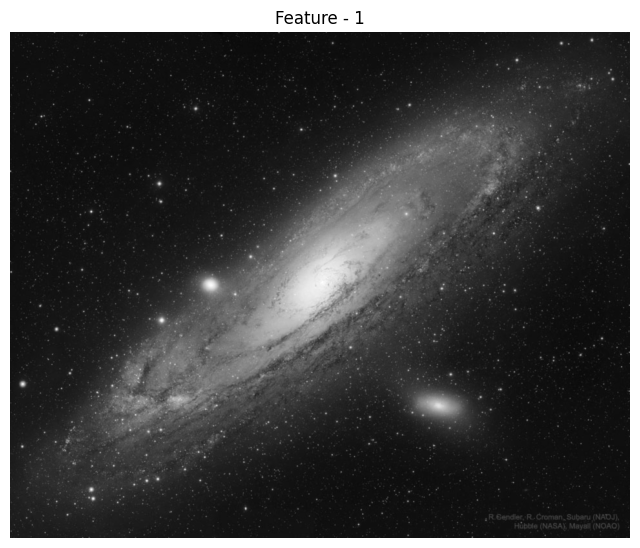

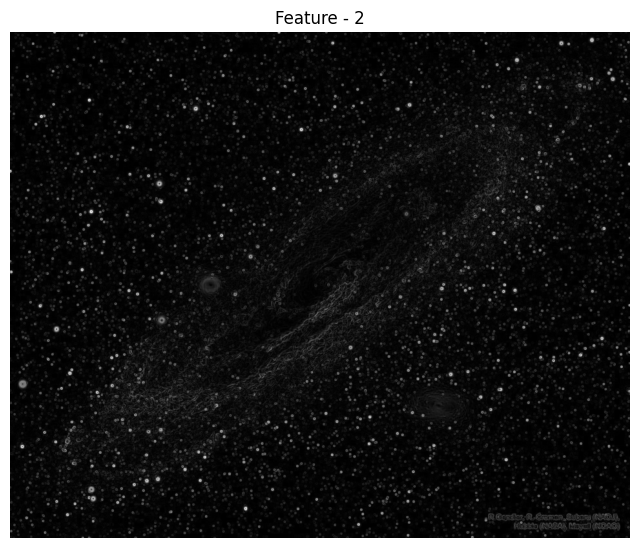

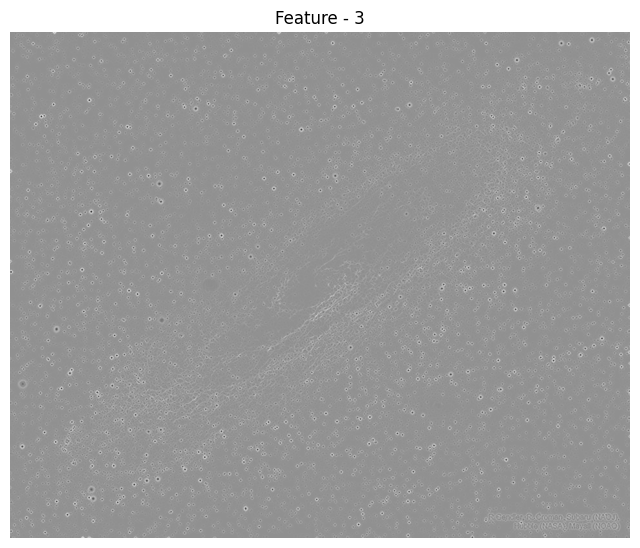

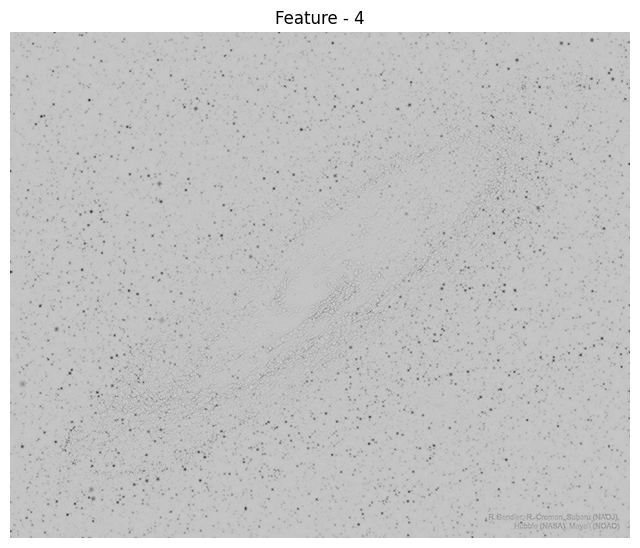

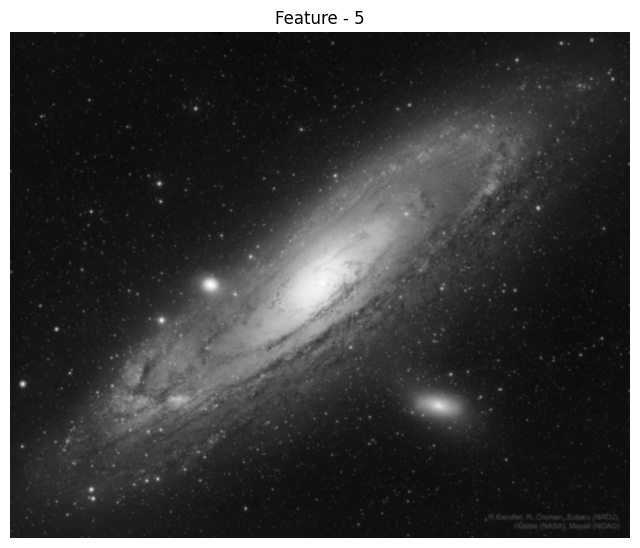

...

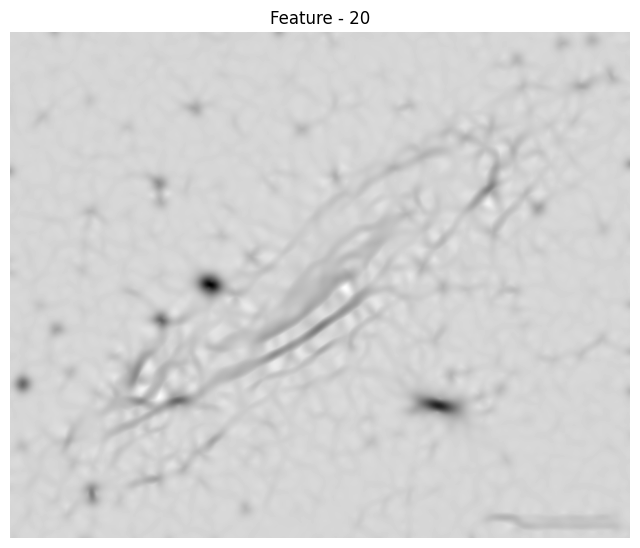

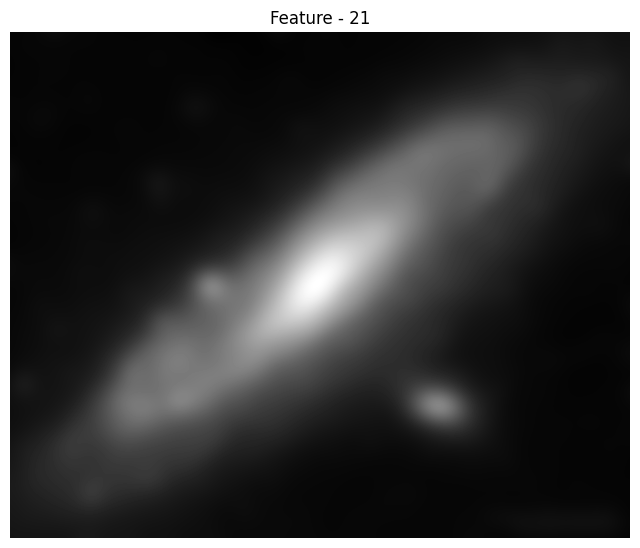

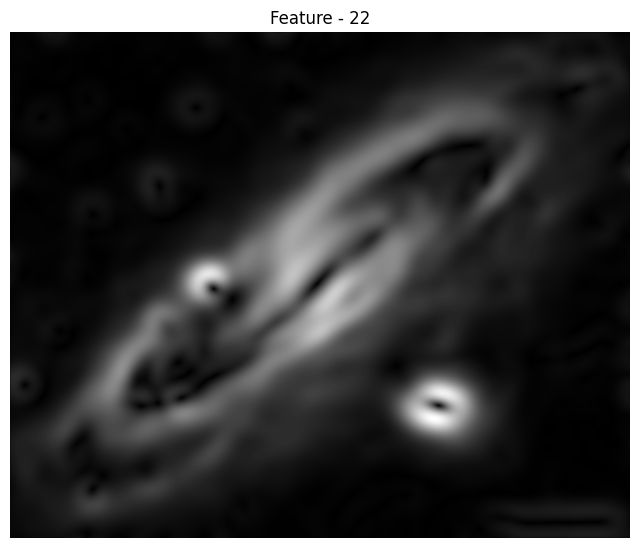

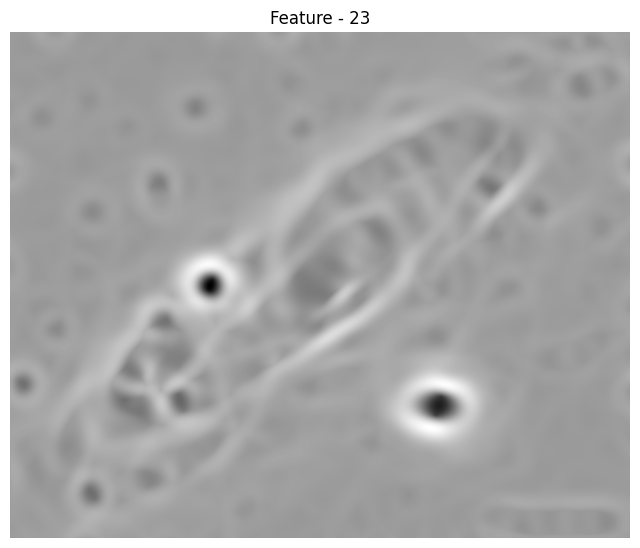

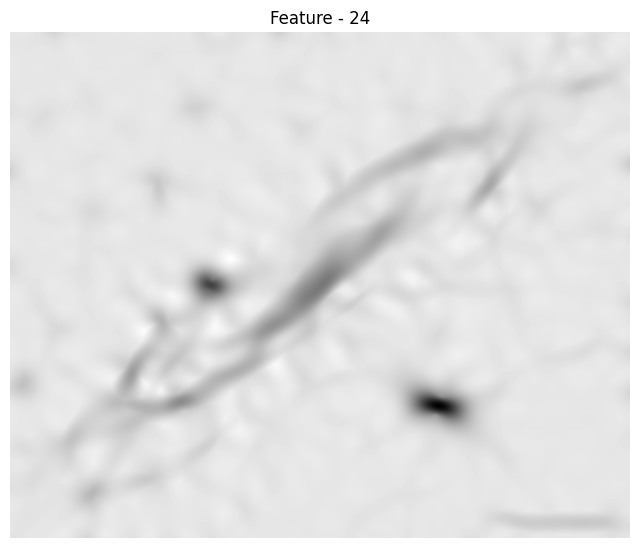

In [ ]:
# Visualize all the features using one colormap
colormap='gray'
for index, feature in enumerate(msbf_features):
  plt.figure(figsize=(8,8))
  plt.imshow(feature, cmap=colormap); plt.axis('off')
  plt.title(f'Feature - {index+1}')
  plt.show()

- Set of four features are shown one after other for 6 times in the output.
- Features 1, 5, 9, 13, 17, 21 --> Gaussian with sigma (0.5, 1, 2, 4, 8, 16)
- Features 2, 6, 10, 14, 18, 22 --> Sobel(Gaussian(sigma))
- (3, 4), (7, 8), (11, 12), (15, 16), (19, 20), (23, 24) --> Each sigma has 2 Textures

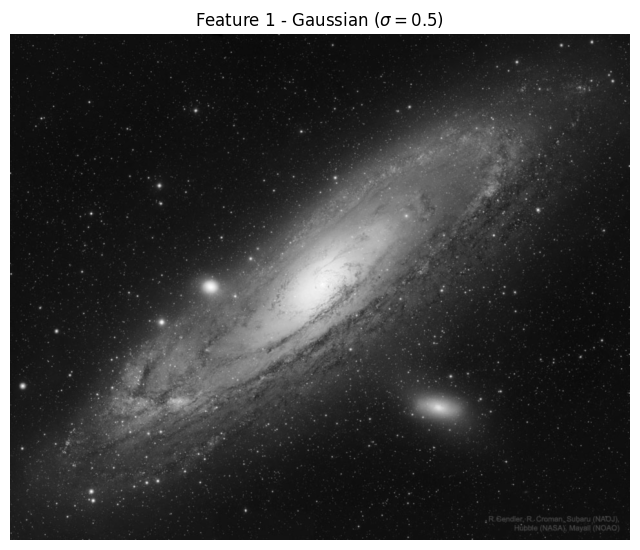

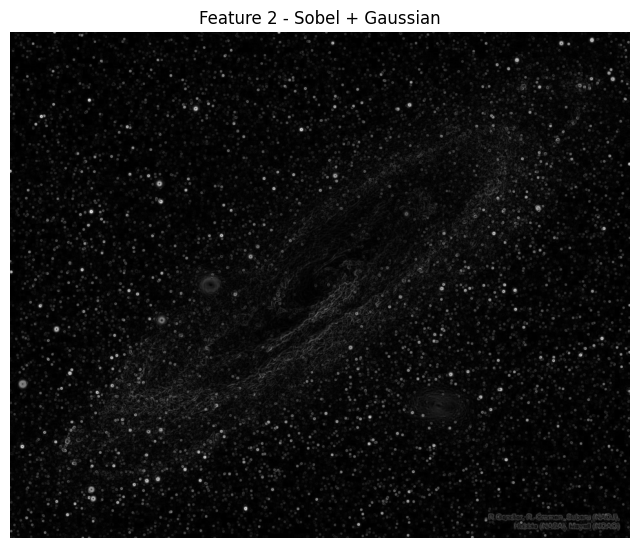

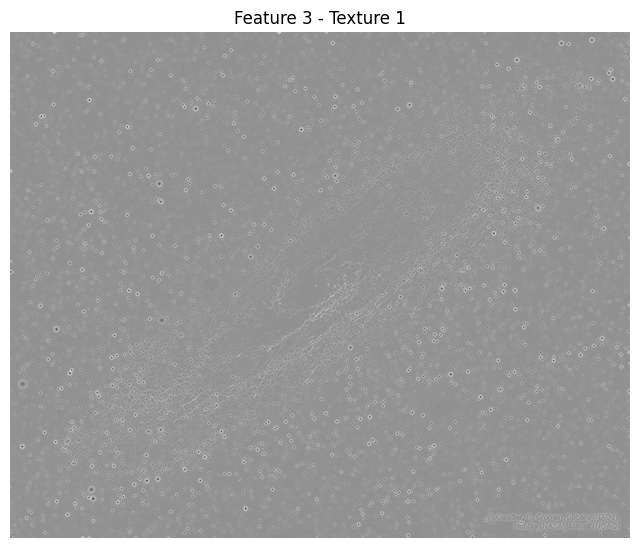

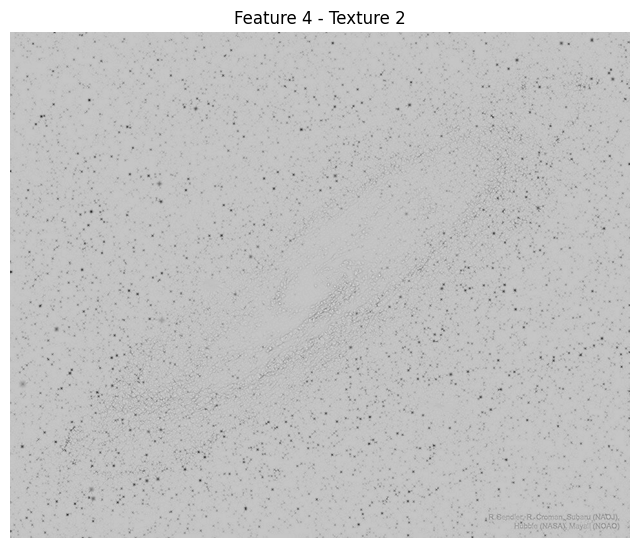

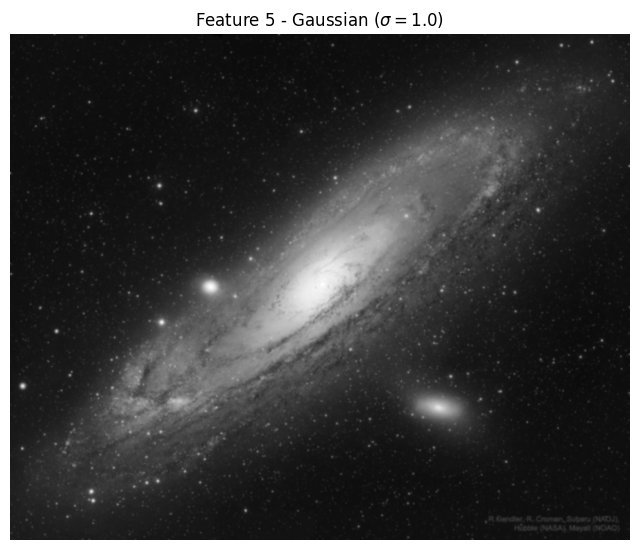

...

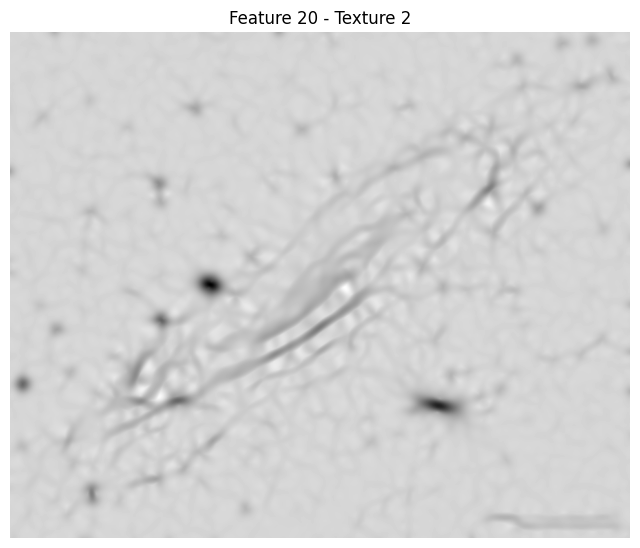

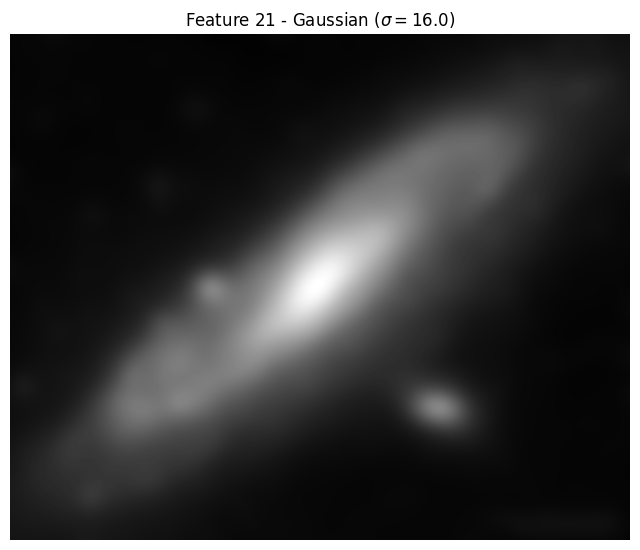

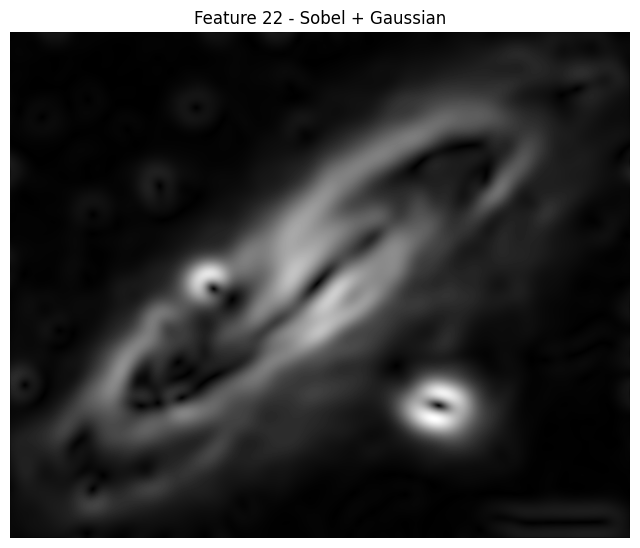

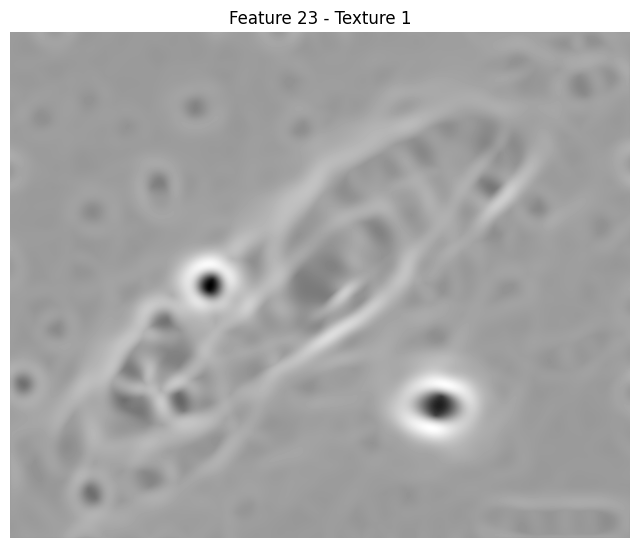

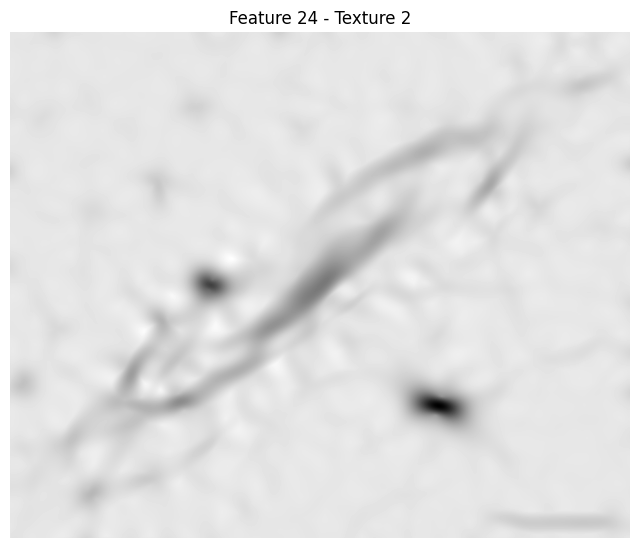

In [32]:
sigma = 0.5
for index, feature in enumerate(msbf_features):
  plt.figure(figsize=(8,8))
  plt.imshow(feature, cmap=colormap); plt.axis('off')
  if index % 4 == 0:
      plt.title(f'Feature {index + 1} - Gaussian ($\sigma={sigma}$)')
      sigma=sigma*2
  elif index % 4 == 1:
      plt.title(f'Feature {index + 1} - Sobel + Gaussian')
  elif index % 4 == 2:
      plt.title(f'Feature {index + 1} - Texture 1')
  else:
      plt.title(f'Feature {index + 1} - Texture 2')
  plt.show()